In [1]:
import os
import urllib.request
import zipfile

# Dataset URL
DATASET_URL = "https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1"

# Project directories
DATA_DIR = "data/ravdess"
ZIP_PATH = os.path.join(DATA_DIR, "ravdess.zip")

os.makedirs(DATA_DIR, exist_ok=True)

# Download dataset
if not os.path.exists(ZIP_PATH):
    print("Downloading RAVDESS...")
    urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)

# Extract dataset
print("Extracting dataset...")
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Dataset ready!")

Extracting dataset...
Dataset ready!


In [2]:
pip install librosa numpy pandas soundfile scikit-learn matplotlib seaborn

In [3]:

import os
import glob
import numpy as np
import pandas as pd
import librosa

# Dataset location
DATA_DIR = "data/ravdess"

# Output file
OUTPUT_FILE = "ravdess_features.csv"

# Emotion labels in RAVDESS
EMOTIONS = {
    "01": "neutral",
    "02": "calm",
    "03": "happy",
    "04": "sad",
    "05": "angry",
    "06": "fearful",
    "07": "disgust",
    "08": "surprised"
}


def extract_features(file_path):

    audio, sr = librosa.load(
        file_path,
        sr=22050,
        mono=True
    )

    features = {}

    # MFCC features
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=40
    )

    for i in range(40):
        features[f"mfcc_{i+1}_mean"] = np.mean(mfcc[i])
        features[f"mfcc_{i+1}_std"] = np.std(mfcc[i])

    # Chroma features
    chroma = librosa.feature.chroma_stft(
        y=audio,
        sr=sr
    )

    for i in range(12):
        features[f"chroma_{i+1}_mean"] = np.mean(chroma[i])
        features[f"chroma_{i+1}_std"] = np.std(chroma[i])

    # Spectral features
    spectral_centroid = librosa.feature.spectral_centroid(
        y=audio, sr=sr
    )

    spectral_bandwidth = librosa.feature.spectral_bandwidth(
        y=audio, sr=sr
    )

    spectral_rolloff = librosa.feature.spectral_rolloff(
        y=audio, sr=sr
    )

    zero_crossing_rate = librosa.feature.zero_crossing_rate(
        y=audio
    )

    rms = librosa.feature.rms(y=audio)

    spectral_features = {
        "spectral_centroid": spectral_centroid,
        "spectral_bandwidth": spectral_bandwidth,
        "spectral_rolloff": spectral_rolloff,
        "zero_crossing_rate": zero_crossing_rate,
        "rms": rms
    }

    for name, values in spectral_features.items():
        features[f"{name}_mean"] = np.mean(values)
        features[f"{name}_std"] = np.std(values)

    return features


def main():

    audio_files = glob.glob(
        os.path.join(DATA_DIR, "**", "*.wav"),
        recursive=True
    )

    print("Total audio files found:", len(audio_files))

    if not audio_files:
        print("No WAV files found. Check dataset extraction.")
        return

    all_data = []

    for index, file_path in enumerate(audio_files):

        filename = os.path.basename(file_path)
        parts = filename.replace(".wav", "").split("-")

        if len(parts) != 7:
            continue

        emotion_code = parts[2]
        actor_id = int(parts[6])

        if emotion_code not in EMOTIONS:
            continue

        try:
            features = extract_features(file_path)

            features["emotion"] = EMOTIONS[emotion_code]
            features["actor_id"] = actor_id
            features["filename"] = filename

            all_data.append(features)

        except Exception as error:
            print("Error processing:", filename, error)

        if (index + 1) % 100 == 0:
            print("Processed:", index + 1)

    # Create DataFrame
    df = pd.DataFrame(all_data)

    # Save CSV
    df.to_csv(OUTPUT_FILE, index=False)

    print("\nFeature extraction completed!")
    print("Total processed:", len(df))
    print("Total features:", len(df.columns) - 3)
    print("Output saved to:", OUTPUT_FILE)

    print("\nEmotion distribution:")
    print(df["emotion"].value_counts())


if __name__ == "__main__":
    main()


Total audio files found: 1440
Processed: 100
Processed: 200
Processed: 300
Processed: 400
Processed: 500
Processed: 600
Processed: 700
Processed: 800
Processed: 900
Processed: 1000
Processed: 1100
Processed: 1200
Processed: 1300
Processed: 1400

Feature extraction completed!
Total processed: 1440
Total features: 114
Output saved to: ravdess_features.csv

Emotion distribution:
emotion
happy        192
disgust      192
angry        192
calm         192
fearful      192
surprised    192
sad          192
neutral       96
Name: count, dtype: int64


In [6]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import *

# Load extracted dataset
if not os.path.exists("ravdess_features.csv"):
    raise FileNotFoundError(
        "Feature CSV not found. Run the feature extraction cell first."
    )

df = pd.read_csv("ravdess_features.csv")

print("Dataset loaded:", df.shape)

# Prepare data
X = df.drop(columns=["emotion", "actor_id", "filename"])
y = df["emotion"]
groups = df["actor_id"]

# Actor-wise split
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.25, random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

# Base classifiers
base_models = [
    ("LR", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ])),
    ("RF", RandomForestClassifier(n_estimators=200, random_state=42)),
    ("SVM", Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ])),
    ("KNN", Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]))
]

# Meta classifiers
meta_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

# Group cross-validation
cv = GroupKFold(n_splits=5)
cv_splits = list(cv.split(X_train, y_train, groups_train))

results = []
trained_models = {}

# Train stacking models
for name, meta in meta_models.items():

    model = StackingClassifier(
        estimators=base_models,
        final_estimator=meta,
        cv=cv_splits,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Meta Classifier": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test, predictions, average="weighted", zero_division=0)
    })

    print("\n", name)
    print(classification_report(y_test, predictions, zero_division=0))

results_df = pd.DataFrame(results)
display(results_df)

results_df.to_csv("stacking_results.csv", index=False)

print("A1 training completed!")


Dataset loaded: (1440, 117)

 Logistic Regression
              precision    recall  f1-score   support

       angry       0.72      0.65      0.68        48
        calm       0.45      0.71      0.55        48
     disgust       0.44      0.29      0.35        48
     fearful       0.44      0.48      0.46        48
       happy       0.47      0.46      0.46        48
     neutral       0.08      0.04      0.05        24
         sad       0.28      0.38      0.32        48
   surprised       0.70      0.48      0.57        48

    accuracy                           0.46       360
   macro avg       0.45      0.43      0.43       360
weighted avg       0.47      0.46      0.46       360


 Random Forest
              precision    recall  f1-score   support

       angry       0.68      0.58      0.63        48
        calm       0.40      0.81      0.54        48
     disgust       0.38      0.31      0.34        48
     fearful       0.39      0.50      0.44        48
       happy

,Meta Classifier,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.461111,0.471050,0.461111,0.455896
1,Random Forest,0.461111,0.484547,0.461111,0.449606
2,SVM,0.461111,0.474206,0.461111,0.456876


A1 training completed!


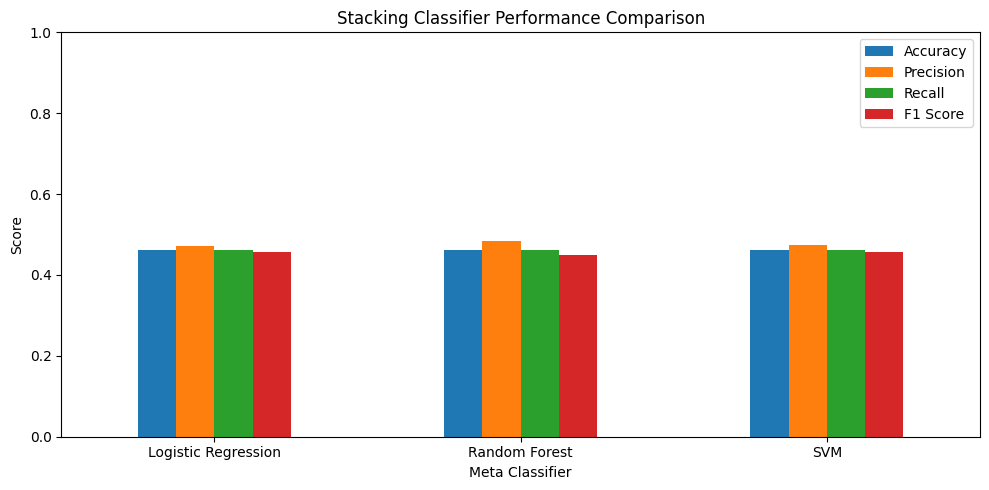

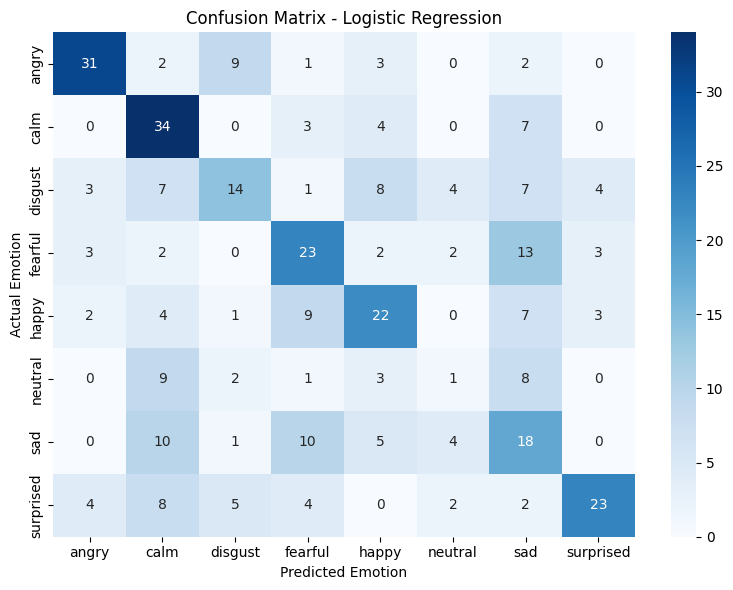

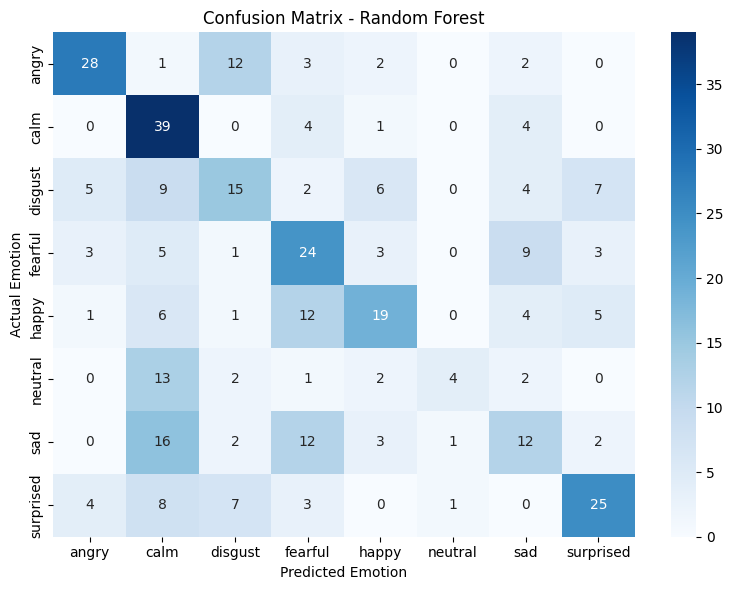

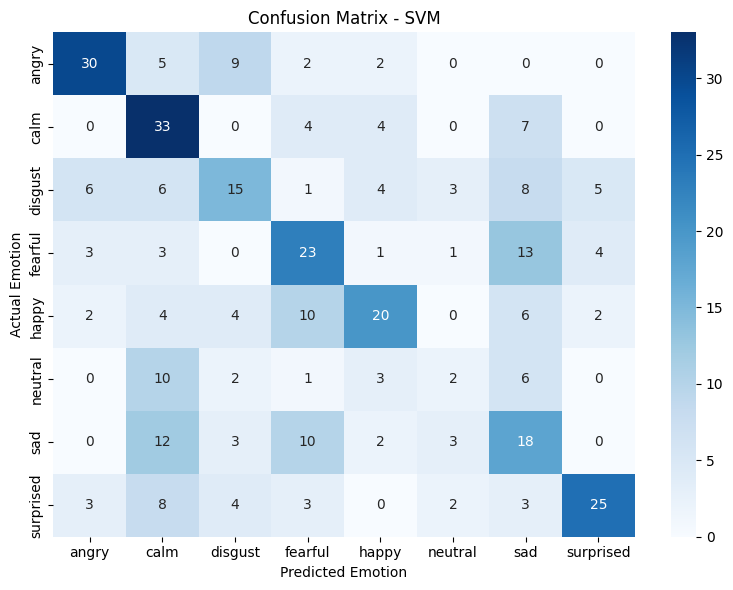

A1 visualization completed!


In [7]:

# 1. Performance comparison graph

results_df.set_index("Meta Classifier")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Stacking Classifier Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("stacking_comparison.png")
plt.show()


# 2. Confusion matrices

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=model.classes_
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Emotion")
    plt.ylabel("Actual Emotion")
    plt.tight_layout()
    plt.savefig(f"confusion_matrix_{name.replace(' ', '_')}.png")
    plt.show()

print("A1 visualization completed!")


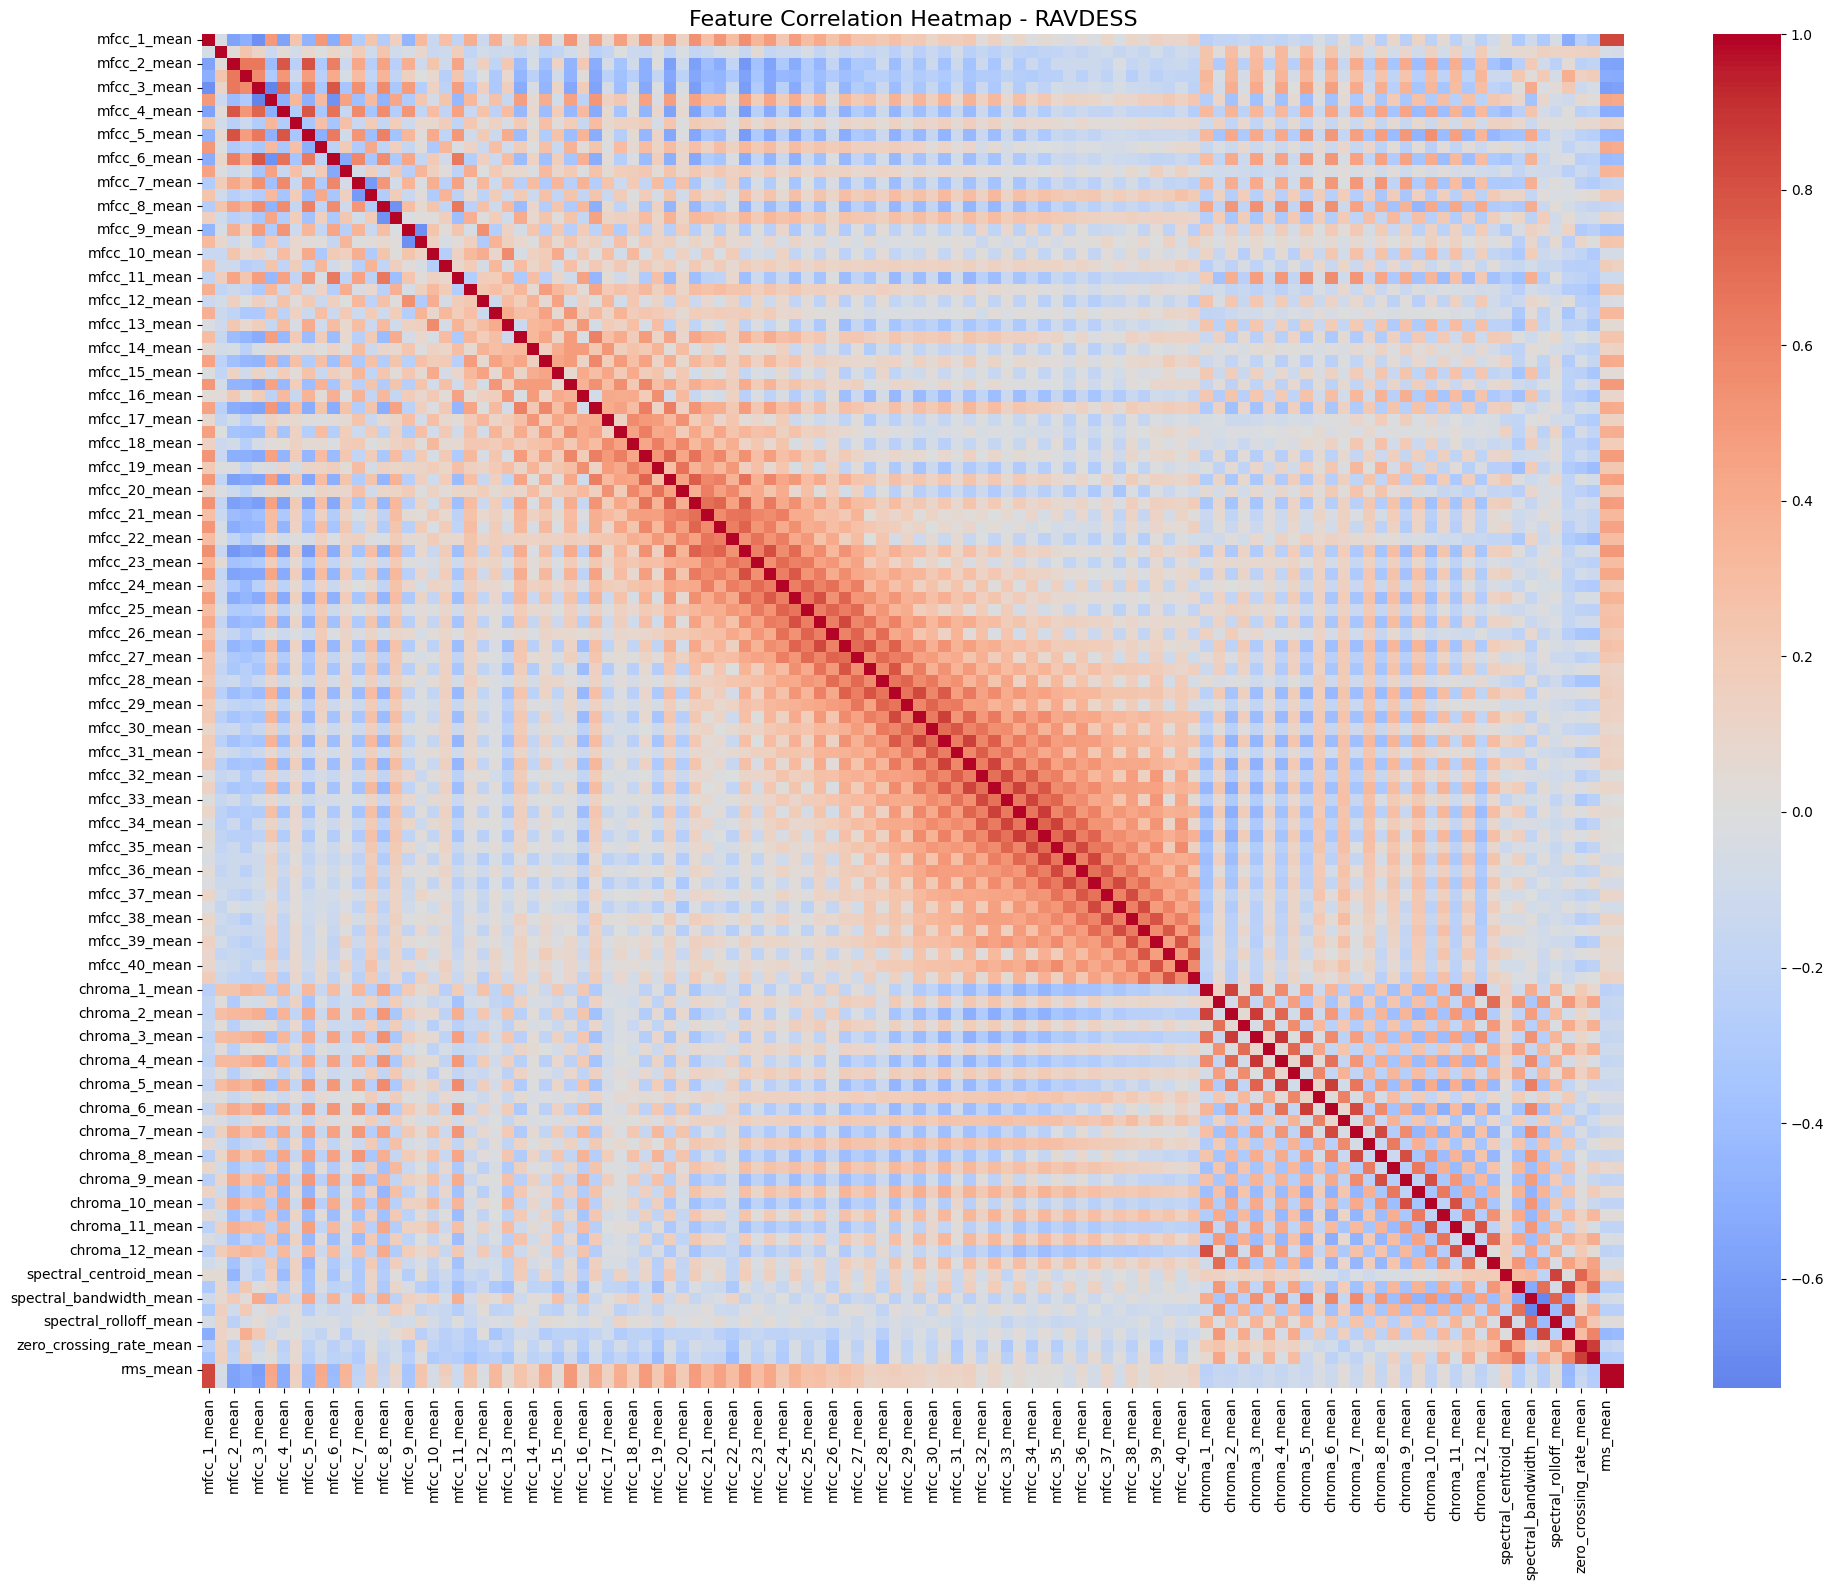

Correlation matrix shape: (114, 114)
A2 correlation analysis completed!


In [8]:

# Select numerical features only
feature_data = df.drop(
    columns=["emotion", "actor_id", "filename"]
)

# Calculate correlation matrix
correlation_matrix = feature_data.corr()

# Display heatmap
plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0,
    cbar=True
)

plt.title("Feature Correlation Heatmap - RAVDESS", fontsize=16)
plt.tight_layout()

plt.savefig("feature_correlation_heatmap.png", dpi=300)
plt.show()

print("Correlation matrix shape:", correlation_matrix.shape)
print("A2 correlation analysis completed!")


In [9]:

from sklearn.decomposition import PCA

# 1. Standardize original features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Apply PCA retaining 99% variance
pca = PCA(n_components=0.99)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train.shape[1])
print("Reduced number of components:", X_train_pca.shape[1])
print("Explained variance:", round(sum(pca.explained_variance_ratio_), 4))

# 3. Define classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

# 4. Train and evaluate PCA-based classifiers
pca_results = []

for name, classifier in classifiers.items():

    classifier.fit(X_train_pca, y_train)

    predictions = classifier.predict(X_test_pca)

    pca_results.append({
        "Classifier": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test, predictions, average="weighted", zero_division=0)
    })

pca_results_df = pd.DataFrame(pca_results)

display(pca_results_df)

pca_results_df.to_csv("pca_results.csv", index=False)

print("PCA classification completed!")


Original number of features: 114
Reduced number of components: 88
Explained variance: 0.9904


,Classifier,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.461111,0.470920,0.461111,0.460486
1,Random Forest,0.366667,0.355215,0.366667,0.349985
2,SVM,0.425000,0.423200,0.425000,0.413158
3,KNN,0.300000,0.305256,0.300000,0.293073


PCA classification completed!
